### 선형회귀(Linear regression)
- 입력과 출력간의 관계를 (선혀으로 놓고) 알아내는 것
    - 광고비와 매출액의 관계
- 목적 : 최적의 기울기와 절편 구하기
    - 실제값과 예측값의 오차가 최소화 되게 구하는 게 목적
    - MSE 사용
- 경사하강법 사용

In [1]:
import torch
import matplotlib.pyplot as plt

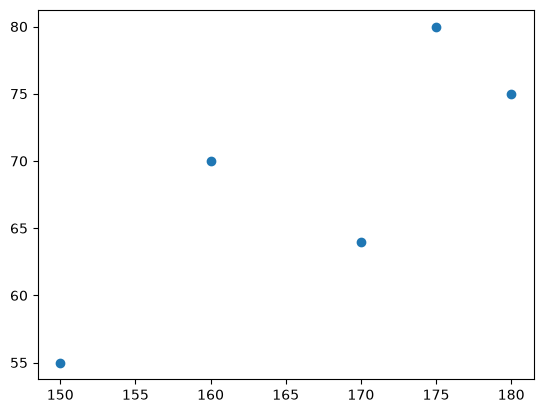

In [2]:
x = torch.tensor([150., 160, 170, 175, 180])
y = torch.tensor([55,70,64,80,75.])
N = len(x)

plt.plot(x,y, 'o')

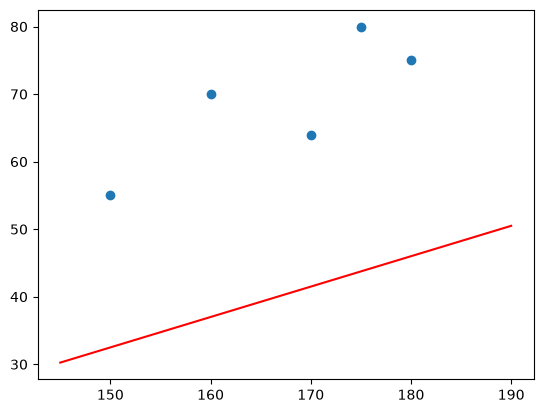

In [4]:
# 임의로 기울기와 절편 설정
a = 0.45    # 기울기
b = -35     # 절편

x_plot = torch.linspace(145,190,100)
y_plot = a*x_plot + b

plt.figure()
plt.plot(x,y,'o')               # 실제 키와 몸무게
plt.plot(x_plot, y_plot, 'r')   # 임의로 만든 선형

(0.0, 1000.0)

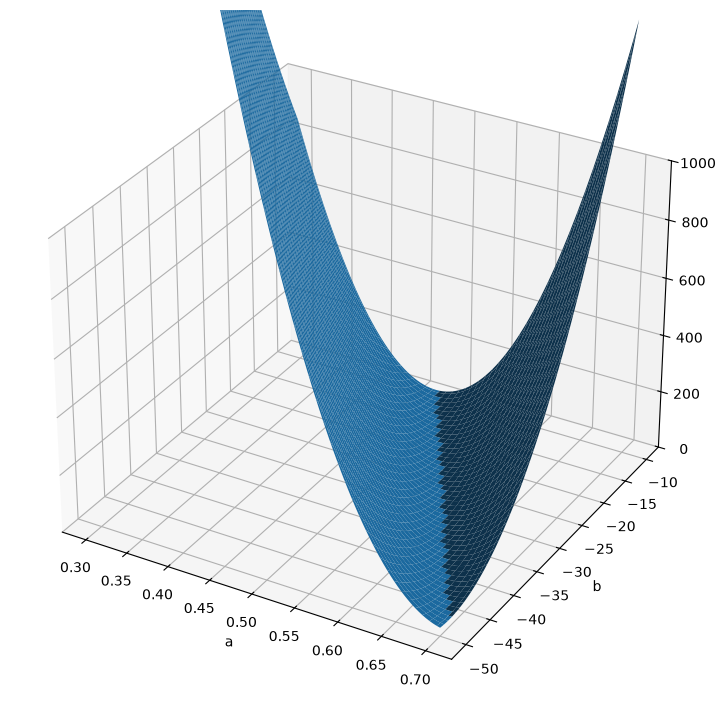

In [29]:
a = 0.5 + torch.linspace(-0.2,0.2,100)      # 0.3 ~ 0.7 기울기 후보군
b = -30 + torch.linspace(-20,20,100)        # -50~-10 절편 후보군

L = torch.zeros(len(a),len(b))

for i in range(len(a)):
    for j in range(len(b)):
        for n in range(N):
            L[i,j] = L[i,j]+(y[n]-(a[i]*x[n]+b[j]))**2

L = L/N #MSE알고리즘

plt.figure(figsize=[10,9])
ax = plt.axes(projection='3d')
A, B = torch.meshgrid(a,b, indexing='ij')

ax.plot_surface(A,B,L)
ax.set_xlabel('a')
ax.set_ylabel('b')
ax.set_zlim([0,1000])

In [14]:
L

tensor([[4645.5547, 4645.5547, 4645.5547,  ..., 4645.5547, 4645.5547,
         4645.5547],
        [4554.1050, 4554.1050, 4554.1050,  ..., 4554.1050, 4554.1050,
         4554.1050],
        [4463.5698, 4463.5698, 4463.5698,  ..., 4463.5698, 4463.5698,
         4463.5698],
        ...,
        [  32.1631,   32.1631,   32.1631,  ...,   32.1631,   32.1631,
           32.1631],
        [  29.4058,   29.4058,   29.4058,  ...,   29.4058,   29.4058,
           29.4058],
        [  27.5628,   27.5628,   27.5628,  ...,   27.5628,   27.5628,
           27.5628]])

In [30]:
print(torch.min(L))
a_opt = A[L == torch.min(L)]
b_opt = B[L == torch.min(L)]

print(f'optimal a = {a_opt}')   # 기울기 최적
print(f'optimal b = {b_opt}')   # 절편 최적

tensor(25.4433)
optimal a = tensor([0.6556])
optimal b = tensor([-40.7071])


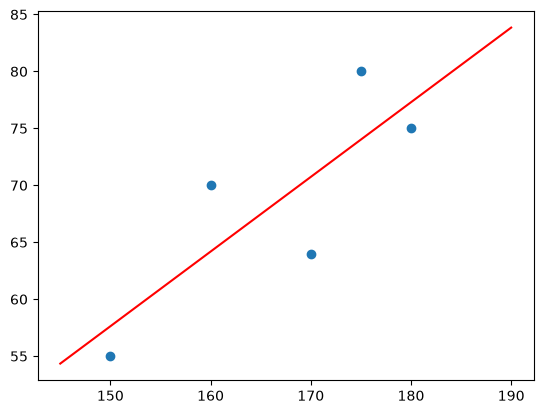

In [31]:
x_plot = torch.linspace(145, 190, 100)
y_plot = a_opt * x_plot + b_opt
plt.plot(x,y,'o')
plt.plot(x_plot, y_plot, 'r')

#### 경사하강법

In [ ]:
a = torch.tensor([0.45], requires_grad=True)
b = torch.tensor([-35.], requires_grad=True)
lr = 3e-6   #0.000003
epoch = 10

loss_history = []

for ep in range(epoch):
    y_hat = a*x+b
    loss = 0
    for n in range(N):
        loss +=(y[n]-y_hat[n])**2
    loss = loss/N

    loss.backward()
    
    with torch.no_grad():
        a -= lr*a.grad
        b -= lr*b.grad
    a.grad = torch.tensor([0.])
    b.grad = torch.tensor([0.])

    loss_history += [loss.item()]

    print(f'Epoch : {ep+1}, train loss : {loss.item():.4f}')
    print(f'Weight : {a.item():.4f}, Bias : {b.item():.4f}')

    # x_plot = torch.linspace(145,190,100)
    # y_plot = a.detach() * x_plot +b.detach()
    # plt.figure()
    # plt.plot(x,y, 'o')
    # plt.plot(x_plot, y_plot, 'r')
    # plt.title(f'Epoch : {ep+1}')
    # plt.show

    print('-'*20)

Epoch : 1, train loss : 851.3125
Weight : 0.4789, Bias : -34.9998
--------------------
Epoch : 2, train loss : 597.1288
Weight : 0.5029, Bias : -34.9997
--------------------
Epoch : 3, train loss : 421.1917
Weight : 0.5228, Bias : -34.9996
--------------------
Epoch : 4, train loss : 299.4146
Weight : 0.5394, Bias : -34.9995
--------------------
Epoch : 5, train loss : 215.1248
Weight : 0.5533, Bias : -34.9994
--------------------
Epoch : 6, train loss : 156.7824
Weight : 0.5648, Bias : -34.9993
--------------------
Epoch : 7, train loss : 116.3997
Weight : 0.5743, Bias : -34.9993
--------------------
Epoch : 8, train loss : 88.4483
Weight : 0.5823, Bias : -34.9992
--------------------
Epoch : 9, train loss : 69.1014
Weight : 0.5889, Bias : -34.9992
--------------------
Epoch : 10, train loss : 55.7102
Weight : 0.5944, Bias : -34.9991
--------------------
Epoch : 11, train loss : 46.4411
Weight : 0.5990, Bias : -34.9991
--------------------
Epoch : 12, train loss : 40.0255
Weight : 0.6

In [ ]:

loss_history =[]

for ep in range(epoch):
    print(x)    # 데이터
    print(a)    # 기울기
    print(b)    # 절편
    y_hat = a* x + b
    print(y_hat)    #몸무게 예측값
    print('-'*30)
    
    # loss 계산
    loss = 0
    for n in range(N):
        loss += (y[n] - y_hat[n])**2
    loss = loss/N

    #update

tensor([150., 160., 170., 175., 180.])
tensor([0.6174], requires_grad=True)
tensor([-34.9990], requires_grad=True)
tensor([57.6066, 63.7803, 69.9540, 73.0408, 76.1277], grad_fn=<AddBackward0>)
------------------------------


d:\assignment\coding\agenticAI\PyTorch\.venv\Lib\site-packages\torch\nn\modules\loss.py:630: UserWarning: Using a target size (torch.Size([5])) that is different to the input size (torch.Size([5, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


Epoch : 1, train loss : 920.072509765625
Weight : 0.4784, Bias : -34.9998


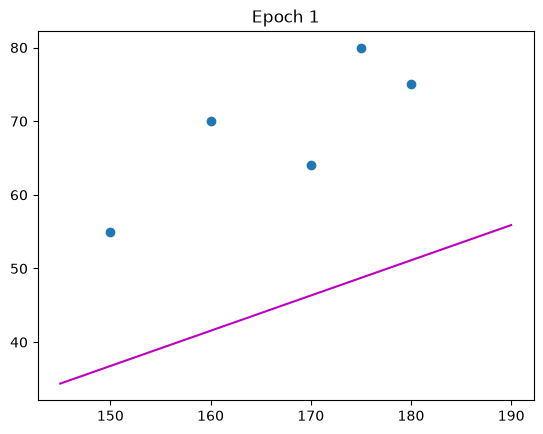

--------------------
Epoch : 2, train loss : 673.9010009765625
Weight : 0.5020, Bias : -34.9997


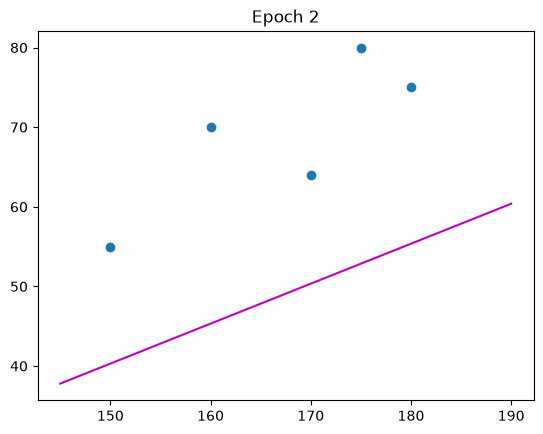

--------------------
Epoch : 3, train loss : 503.5098876953125
Weight : 0.5217, Bias : -34.9996


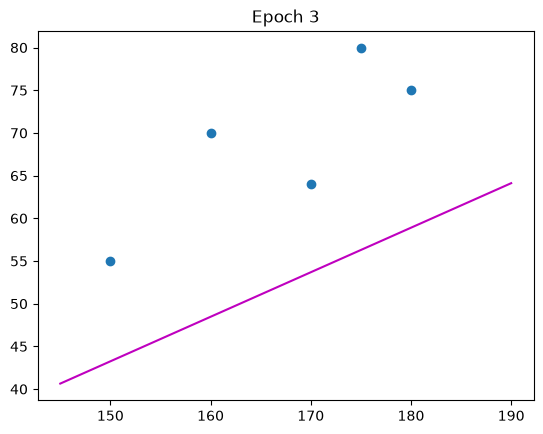

--------------------
Epoch : 4, train loss : 385.5712585449219
Weight : 0.5380, Bias : -34.9995


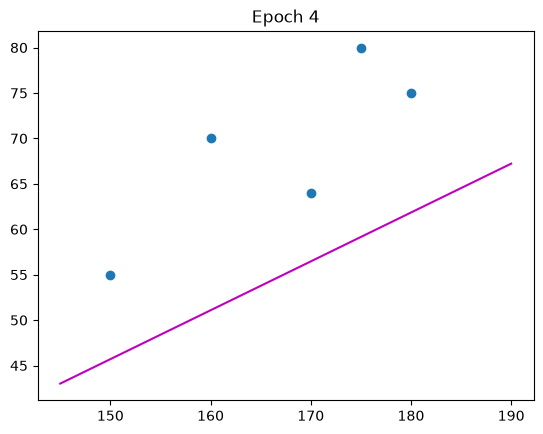

--------------------
Epoch : 5, train loss : 303.9385986328125
Weight : 0.5516, Bias : -34.9994


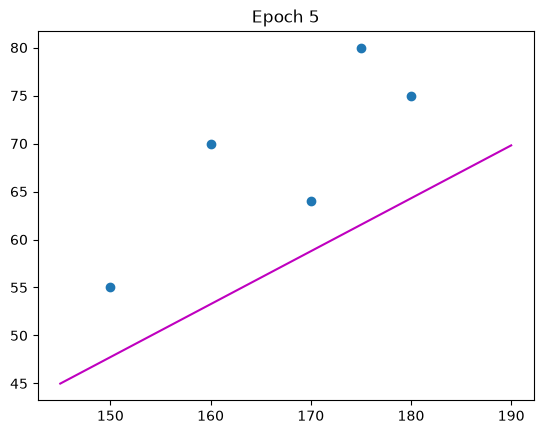

--------------------
Epoch : 6, train loss : 247.43504333496094
Weight : 0.5629, Bias : -34.9993


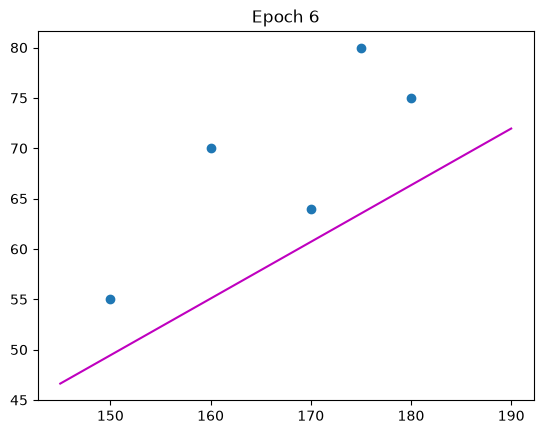

--------------------
Epoch : 7, train loss : 208.32546997070312
Weight : 0.5724, Bias : -34.9993


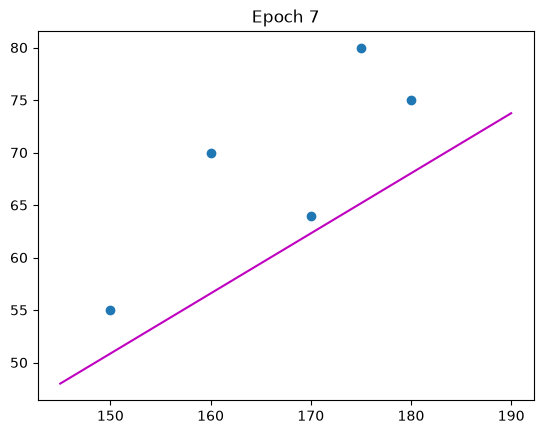

--------------------
Epoch : 8, train loss : 181.25523376464844
Weight : 0.5802, Bias : -34.9992


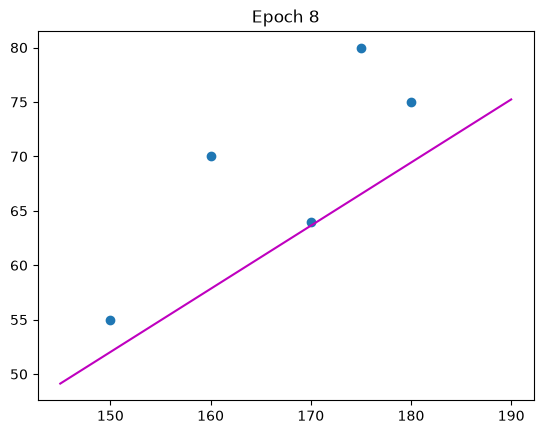

--------------------
Epoch : 9, train loss : 162.5181884765625
Weight : 0.5867, Bias : -34.9992


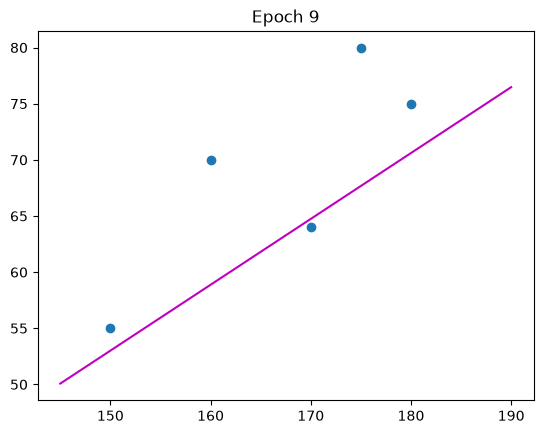

--------------------
Epoch : 10, train loss : 149.54905700683594
Weight : 0.5921, Bias : -34.9991


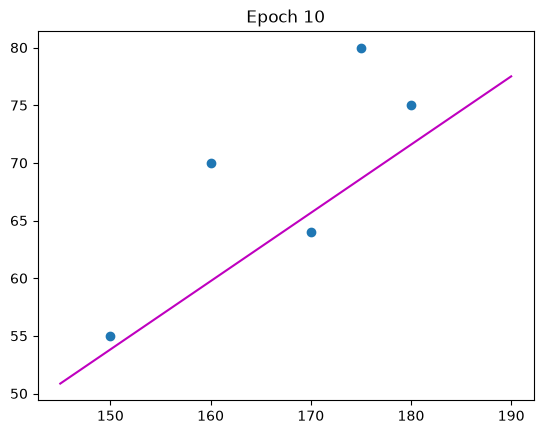

--------------------
Epoch : 11, train loss : 140.57228088378906
Weight : 0.5966, Bias : -34.9991


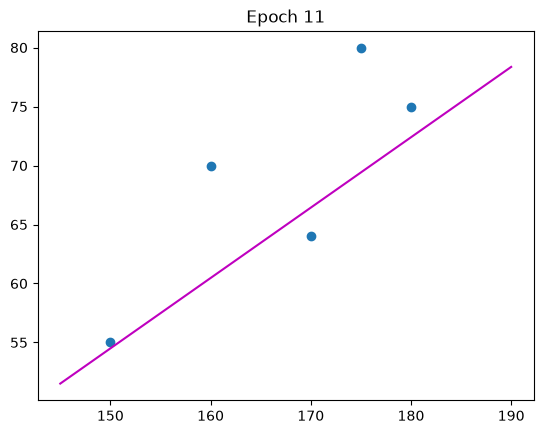

--------------------
Epoch : 12, train loss : 134.3588409423828
Weight : 0.6004, Bias : -34.9991


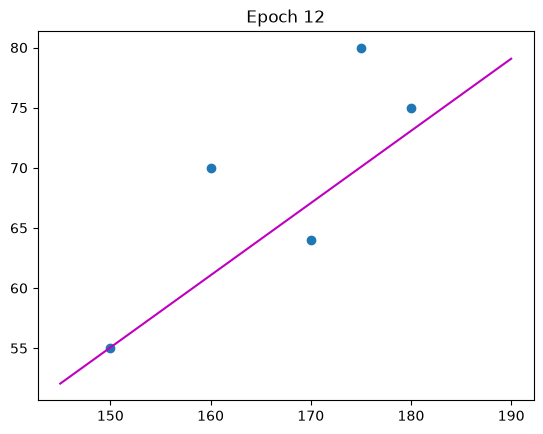

--------------------
Epoch : 13, train loss : 130.05812072753906
Weight : 0.6035, Bias : -34.9991


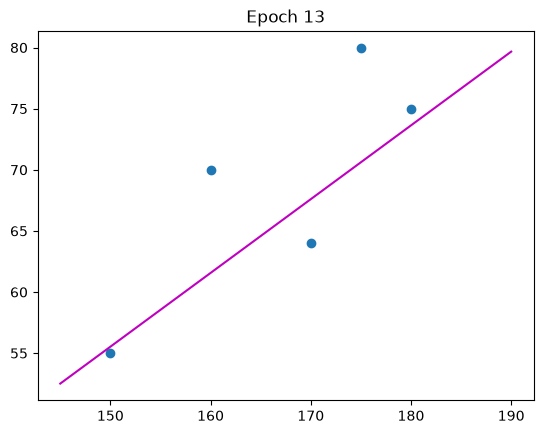

--------------------
Epoch : 14, train loss : 127.08136749267578
Weight : 0.6061, Bias : -34.9990


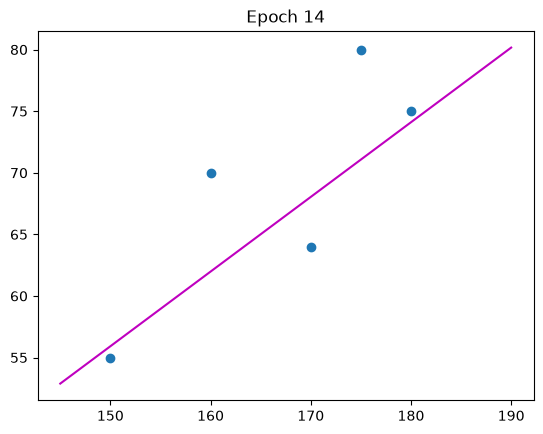

--------------------
Epoch : 15, train loss : 125.0208969116211
Weight : 0.6083, Bias : -34.9990


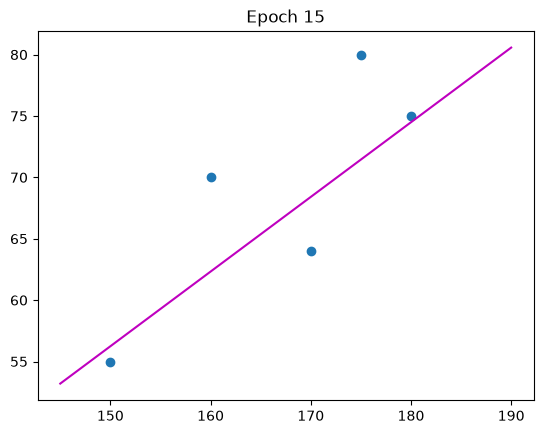

--------------------
Epoch : 16, train loss : 123.59478759765625
Weight : 0.6101, Bias : -34.9990


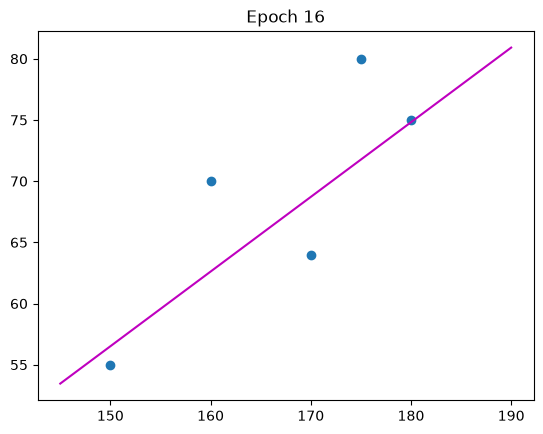

--------------------
Epoch : 17, train loss : 122.60765838623047
Weight : 0.6116, Bias : -34.9990


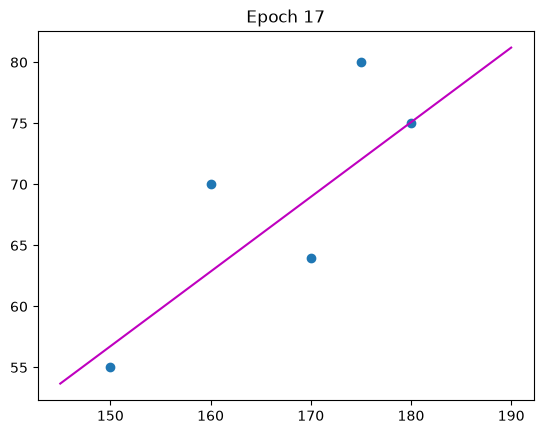

--------------------
Epoch : 18, train loss : 121.92437744140625
Weight : 0.6128, Bias : -34.9990


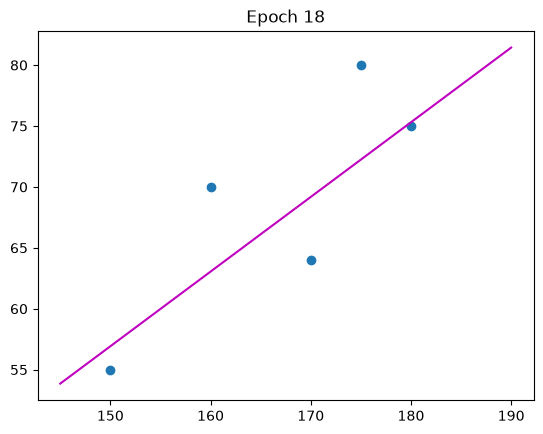

--------------------
Epoch : 19, train loss : 121.45140838623047
Weight : 0.6138, Bias : -34.9990


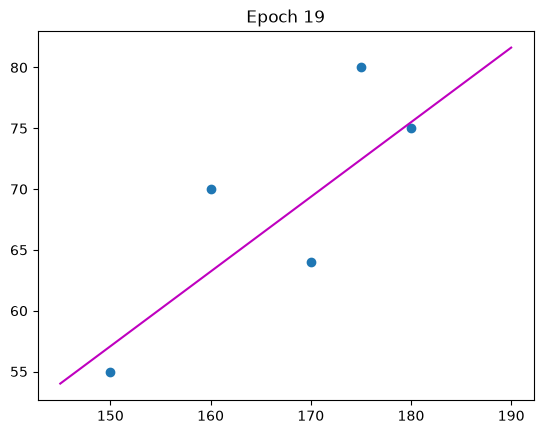

--------------------
Epoch : 20, train loss : 121.12413024902344
Weight : 0.6147, Bias : -34.9990


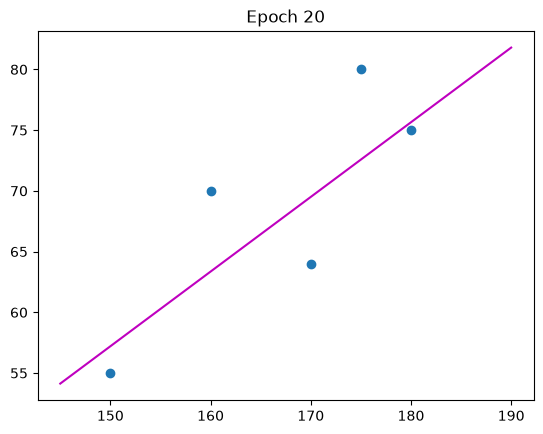

--------------------


In [35]:
# 위는 어떻게 실행되는지 알기위해 한 것(근데 모르겠음 ㅠ)
# 여기서부터 PyTorch 정석
from torch import nn, optim

x = x.reshape(-1,1)

model = nn.Linear(1,1)
model.weight.data = torch.tensor([[0.45]])
model.bias.data = torch.tensor([-35.])

LR = 3e-6
EPOCH = 20

optimizer = optim.SGD(model.parameters(), lr= LR)
cirterion = nn.MSELoss()

loss_history = []

for ep in range(EPOCH):
    #예측값
    y_hat = model(x)

    #loss
    loss = cirterion(y_hat, y)

    # update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # 출력은 본인 마음대로
    loss_history += [loss.item()]
    print(f'Epoch : {ep+1}, train loss : {loss.item()}')
    print(f'Weight : {model.weight.data.item():.4f}, Bias : {model.bias.data.item():.4f}')

    x_plot = torch.linspace(145,190,100)
    y_plot = model.weight.squeeze().detach()*x_plot + model.bias.detach()
    plt.figure()
    plt.plot(x,y,'o')
    plt.plot(x_plot, y_plot, 'm')
    plt.title(f'Epoch {ep+1}')
    plt.show()
    print('-'*20)
